# CCNLP CCA3 — A Proverb-Interpretation Benchmark for Language Models

**Group 16** &nbsp;|&nbsp; Panel B &nbsp;|&nbsp; School of Computer Science & Engineering, MIT-WPU

| Member | PRN | Experiment (notebook) |
|---|---|---|
| Sahish Nagulwar | 1032233310 | Reverse retrieval: situation to proverb (Plan A 2.8) |
| Ibrahim Ansari | 1032233145 | Idiom identification in running text (Plan A 2.5) |
| **Chayan Raj Bharati** | 1032233134 | **Language-model interpretation benchmark (Plan A 2.7)** |

**Team problem statement:** *Develop a multilingual NLP framework that identifies Indian idioms and distinguishes their literal meaning from culturally intended figurative meaning across Indian languages, while modeling cultural context and linguistic variation.*

**Research question (Chayan Raj Bharati):** When a small open language model is asked what a proverb means, does its answer come closer to the compiler's recorded meaning than the proverb's own literal text does, and does that hold when the input is the romanized source language rather than English?

CCA1 found that a multilingual embedding model gave nothing on romanized text. This notebook asks the same question of generative models. Two open instruction-tuned models from different families, Qwen2.5-0.5B-Instruct (494M parameters, chat) and FLAN-T5-base (250M, sequence-to-sequence), are prompted for a one-sentence meaning of each proverb under two inputs, and scored against the compiler's explanation with controls that separate interpretation from restatement.

The three CCA1 corpora (545 Marathi, 344 Hindi, 103 Assamese proverbs, each with a romanized text, a literal English translation and the compiler's explanation of the intended meaning) are reused from `../cca1/`. Everything here runs on CPU.

In [1]:
import json, random, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)
os.makedirs('report', exist_ok=True)
metrics = {}

LANGS = [('marathi', 'Marathi'), ('hindi', 'Hindi'), ('assamese', 'Assamese')]
CORPUS = '../cca1/corpus/PanelB_16_{}_proverbs.csv'
corpora = {l: pd.read_csv(CORPUS.format(l)) for l, _ in LANGS}
with_expl = {l: df[df.commentary.fillna('').str.len() > 20].reset_index(drop=True) for l, df in corpora.items()}
for l, L in LANGS:
    print(f'{L}: {len(corpora[l])} proverbs, {len(with_expl[l])} with explanations')

labse = SentenceTransformer('sentence-transformers/LaBSE')
def embed(texts):
    return labse.encode(list(texts), show_progress_bar=False, normalize_embeddings=True)

/home/ibu/Documents/collegework/sem7/ccnlp/cca1/.venv/lib64/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Marathi: 545 proverbs, 338 with explanations
Hindi: 344 proverbs, 305 with explanations
Assamese: 103 proverbs, 75 with explanations


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4845.25it/s]

## 1. Set-up

60 proverbs with explanations per language (random sample, seed 42; Assamese has 75 in total). Score: LaBSE cosine similarity between the model's answer and the gold explanation. Control: similarity between the same answer and a random other explanation; the margin between the two is what counts. Echo baseline: the literal translation itself, scored the same way, which is what a model gets for merely restating the proverb.

In [2]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
import torch
torch.set_num_threads(4)
MODELS = ['Qwen/Qwen2.5-0.5B-Instruct', 'google/flan-t5-base']
loaded = {}
def load(name):
    if name not in loaded:
        tok = AutoTokenizer.from_pretrained(name)
        if 't5' in name:
            mdl = AutoModelForSeq2SeqLM.from_pretrained(name)
        else:
            tok.padding_side = 'left'; mdl = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32)
        loaded[name] = (tok, mdl)
    return loaded[name]

def ask(name, texts, batch=8):
    tok, mdl = load(name)
    prompts = [f'Explain the meaning of this proverb in one sentence: "{t}"' for t in texts]
    out = []
    for i in range(0, len(prompts), batch):
        if 't5' in name:
            enc = tok(prompts[i:i + batch], return_tensors='pt', padding=True, truncation=True, max_length=96)
            with torch.no_grad():
                gen = mdl.generate(**enc, max_new_tokens=48, num_beams=2)
            out += tok.batch_decode(gen, skip_special_tokens=True)
        else:
            chats = [tok.apply_chat_template([{'role': 'user', 'content': p}], tokenize=False, add_generation_prompt=True) for p in prompts[i:i + batch]]
            enc = tok(chats, return_tensors='pt', padding=True)
            with torch.no_grad():
                gen = mdl.generate(**enc, max_new_tokens=48, do_sample=False)
            out += [tok.decode(g[enc['input_ids'].shape[1]:], skip_special_tokens=True).strip() for g in gen]
    return out

## 2. Running the benchmark on the three corpora

In [3]:
per_item = []
answers = {}
for l, L in LANGS:
    df = with_expl[l]
    bench = df if len(df) <= 60 else df.sample(60, random_state=42).reset_index(drop=True)
    gold = embed(bench.commentary.tolist()); control = gold[rng.permutation(len(gold))]
    systems = {}
    for name in MODELS:
        for cond, col in [('literal_en', 'literal_en'), ('romanized', 'proverb_translit')]:
            ans = ask(name, bench[col].tolist()); A = embed(ans)
            answers[(l, name, cond)] = ans
            systems[f'{name.split("/")[1].replace("-Instruct", "")} / {cond}'] = A
    systems['echo baseline'] = embed(bench.literal_en.tolist())
    for sysname, A in systems.items():
        sg = (A * gold).sum(axis=1); sc = (A * control).sum(axis=1)
        for i in range(len(bench)):
            per_item.append({'language': L, 'system': sysname, 'sim_gold': float(sg[i]), 'sim_control': float(sc[i]), 'margin': float(sg[i] - sc[i])})
    print(L, 'done,', len(bench), 'proverbs')
per_item = pd.DataFrame(per_item)
bench_tbl = per_item.groupby(['language', 'system'])[['sim_gold', 'sim_control', 'margin']].mean().round(3)
metrics['benchmark'] = {f'{L}/{s}': bench_tbl.loc[(L, s)].to_dict() for L, s in bench_tbl.index}
bench_tbl

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<03:15,  1.48it/s]

Loading weights:  14%|█▍        | 41/290 [00:00<00:03, 64.69it/s]

Loading weights:  43%|████▎     | 124/290 [00:01<00:01, 138.19it/s]

Loading weights:  51%|█████▏    | 149/290 [00:01<00:00, 144.13it/s]

Loading weights:  84%|████████▍ | 245/290 [00:01<00:00, 218.03it/s]

... (10 outputs left out)

Marathi done, 60 proverbs


Hindi done, 60 proverbs


Assamese done, 60 proverbs


sim_gold  sim_control  margin
language system                                                  
Assamese Qwen2.5-0.5B / literal_en     0.267        0.221   0.046
         Qwen2.5-0.5B / romanized      0.214        0.208   0.007
         echo baseline                 0.218        0.132   0.086
         flan-t5-base / literal_en     0.156        0.097   0.058
         flan-t5-base / romanized      0.098        0.106  -0.008
Hindi    Qwen2.5-0.5B / literal_en     0.110        0.059   0.051
         Qwen2.5-0.5B / romanized      0.076        0.071   0.005
         echo baseline                 0.125        0.053   0.073
         flan-t5-base / literal_en     0.113        0.063   0.049
         flan-t5-base / romanized      0.097        0.095   0.002
Marathi  Qwen2.5-0.5B / literal_en     0.138        0.096   0.042
         Qwen2.5-0.5B / romanized      0.113        0.097   0.016
         echo baseline                 0.166        0.089   0.077
         flan-t5-base / literal_en     0.143        0.079   0.064
         flan-t5-base / romanized      0.059        0.044   0.015

## 3. Results

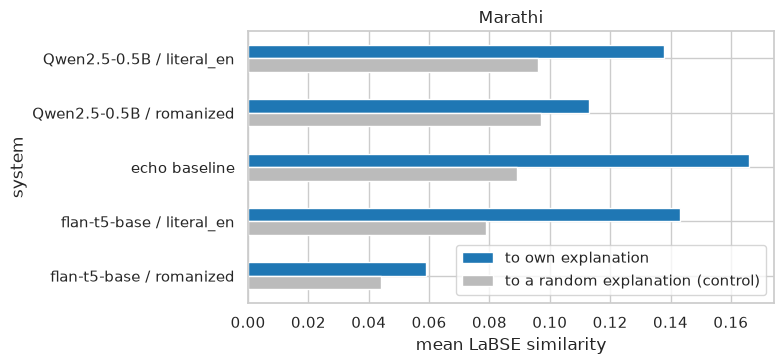

In [4]:
sub = bench_tbl.loc['Marathi']
fig, ax = plt.subplots(figsize=(8, 3.8))
sub[['sim_gold', 'sim_control']].plot.barh(ax=ax, color=['#1f77b4', '#bbbbbb']); ax.invert_yaxis()
ax.set_xlabel('mean LaBSE similarity'); ax.set_title('Marathi'); ax.legend(['to own explanation', 'to a random explanation (control)'], loc='lower right')
plt.tight_layout(); plt.show()

**Figure 1: Marathi: mean similarity of each system's answer to the compiler's explanation (blue) against the control (grey), for both inputs and the echo baseline.**

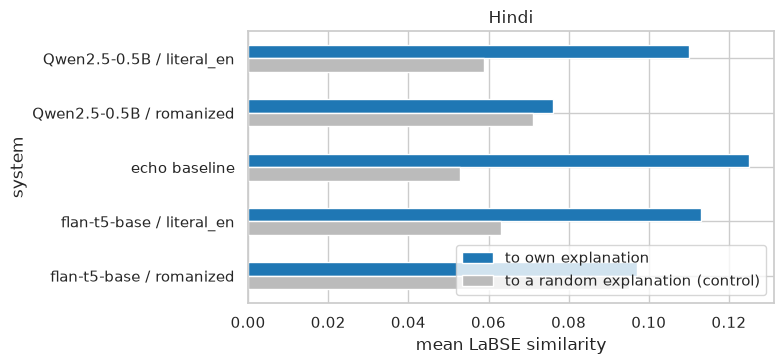

In [5]:
sub = bench_tbl.loc['Hindi']
fig, ax = plt.subplots(figsize=(8, 3.8))
sub[['sim_gold', 'sim_control']].plot.barh(ax=ax, color=['#1f77b4', '#bbbbbb']); ax.invert_yaxis()
ax.set_xlabel('mean LaBSE similarity'); ax.set_title('Hindi'); ax.legend(['to own explanation', 'to a random explanation (control)'], loc='lower right')
plt.tight_layout(); plt.show()

**Figure 2: Hindi: mean similarity of each system's answer to the compiler's explanation (blue) against the control (grey), for both inputs and the echo baseline.**

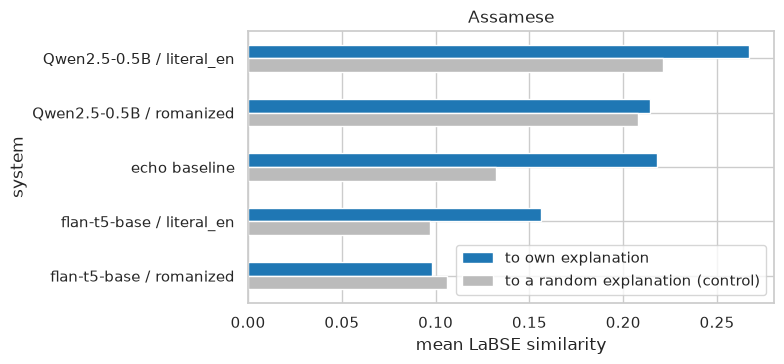

In [6]:
sub = bench_tbl.loc['Assamese']
fig, ax = plt.subplots(figsize=(8, 3.8))
sub[['sim_gold', 'sim_control']].plot.barh(ax=ax, color=['#1f77b4', '#bbbbbb']); ax.invert_yaxis()
ax.set_xlabel('mean LaBSE similarity'); ax.set_title('Assamese'); ax.legend(['to own explanation', 'to a random explanation (control)'], loc='lower right')
plt.tight_layout(); plt.show()

**Figure 3: Assamese: mean similarity of each system's answer to the compiler's explanation (blue) against the control (grey), for both inputs and the echo baseline.**

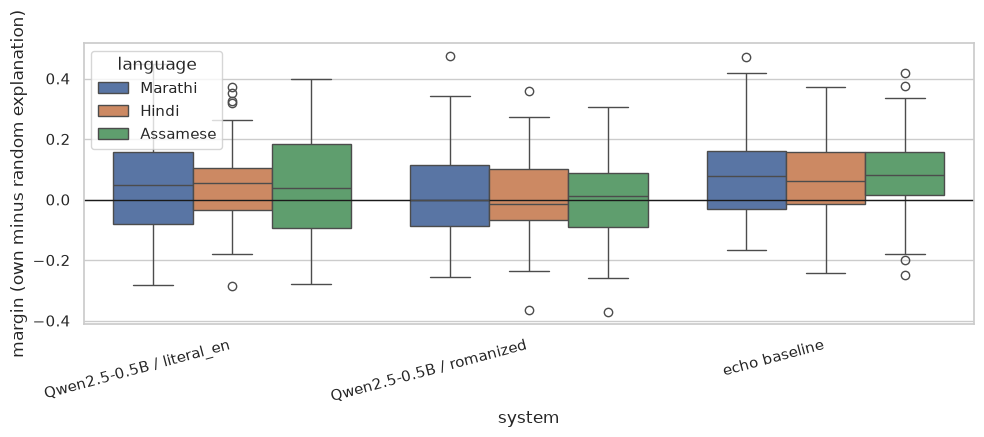

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=per_item[per_item.system.str.contains('Qwen|echo')], x='system', y='margin', hue='language', ax=ax)
ax.axhline(0, color='k', lw=1); ax.set_ylabel('margin (own minus random explanation)'); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.show()

**Figure 4: Per-proverb margin distributions for the Qwen conditions and the echo baseline, by language. A margin above zero means the answer is closer to the right explanation than to a random one.**

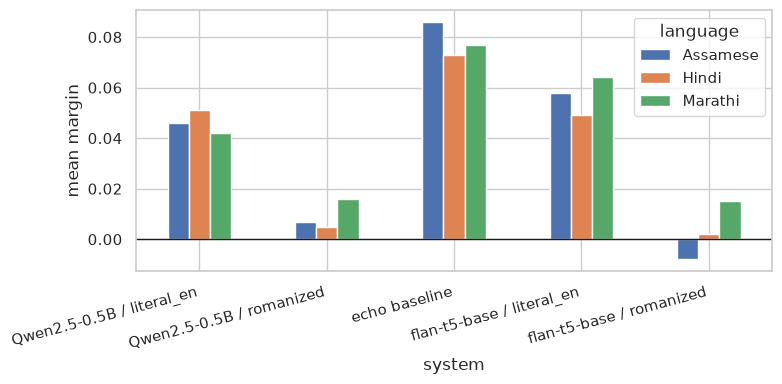

In [8]:
m = bench_tbl['margin'].unstack('language')
fig, ax = plt.subplots(figsize=(8, 4))
m.plot.bar(ax=ax); ax.axhline(0, color='k', lw=1); ax.set_ylabel('mean margin'); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.show()

**Figure 5: Mean margin per system across the three languages. The echo baseline is the bar each model has to beat.**

In [9]:
pd.set_option('display.max_colwidth', 110)
l = 'hindi'; df = with_expl[l]; bench = df.sample(60, random_state=42).reset_index(drop=True)
ex = pd.DataFrame({'proverb (literal)': bench.literal_en.head(5), 'gold meaning': bench.commentary.head(5),
                   'Qwen answer': answers[(l, 'Qwen/Qwen2.5-0.5B-Instruct', 'literal_en')][:5],
                   'FLAN-T5 answer': answers[(l, 'google/flan-t5-base', 'literal_en')][:5]})
ex

,proverb (literal),gold meaning,Qwen answer,FLAN-T5 answer
0,It is uo market without the shameless weiioh.,Proatitutea aiu always to he found at mar kata iu ludia.,"The proverb ""It is a market without the shameless ego"" means that success or prosperity can only be achiev...",it is uo market without the shameless weioh.
1,"I will plaster thee, oM, if a rich man die I","The prayer of the Achtiaj BrShman, who get the rich covering in which the corpse is wrapped, besides other...","The proverb ""I will plaster thee, O M, if a rich man die I"" means that if someone dies and is buried with ...","will plaster thee, oM, if a rich man die I"
2,"Litigation is wrong, possession is right. I",Poaaaaaion ia nine pointa of the law.,"The proverb ""Litigation is wrong, possession is right"" suggests that when someone seeks to gain control or...",'m not a thief
3,The strong man is eeetj body’s son-in-law.,R% hshsBte are obejed.,"In this proverb, ""eeetj"" refers to a powerful or influential individual who has a significant influence ov...",the strong man is the body’s son-in-law.
4,"Nurse, may you have seven brothers 1",&id by children in blindnaan’s buff.,"The proverb ""Nurse, may you have seven brothers"" suggests that the nurse should be patient and kind to her...",a nurse may have seven brothers 1


Five Hindi examples with both models' answers next to the gold explanation, so the scores can be read against what the models actually wrote.

## 4. The interface

`explain()` is what a chatbot calls: it returns the model's one-sentence meaning and, when the proverb is in the corpus, the compiler's recorded meaning next to it.

In [10]:
def explain(text, name='Qwen/Qwen2.5-0.5B-Instruct'):
    return ask(name, [text])[0]
print(explain('Perpetual crops, perpetual poverty.'))

"Perpetual crops and perpetual poverty" means that whatever you plant will eventually yield its own harvest, leaving behind nothing but barren land and endless suffering.


In [11]:
json.dump(metrics, open('report/PanelB_16_CCA3_v2_llm_benchmark_metrics.json', 'w'), indent=1)
print(json.dumps(metrics, indent=1)[:2000])

{
 "benchmark": {
  "Assamese/Qwen2.5-0.5B / literal_en": {
   "sim_gold": 0.267,
   "sim_control": 0.221,
   "margin": 0.046
  },
  "Assamese/Qwen2.5-0.5B / romanized": {
   "sim_gold": 0.214,
   "sim_control": 0.208,
   "margin": 0.007
  },
  "Assamese/echo baseline": {
   "sim_gold": 0.218,
   "sim_control": 0.132,
   "margin": 0.086
  },
  "Assamese/flan-t5-base / literal_en": {
   "sim_gold": 0.156,
   "sim_control": 0.097,
   "margin": 0.058
  },
  "Assamese/flan-t5-base / romanized": {
   "sim_gold": 0.098,
   "sim_control": 0.106,
   "margin": -0.008
  },
  "Hindi/Qwen2.5-0.5B / literal_en": {
   "sim_gold": 0.11,
   "sim_control": 0.059,
   "margin": 0.051
  },
  "Hindi/Qwen2.5-0.5B / romanized": {
   "sim_gold": 0.076,
   "sim_control": 0.071,
   "margin": 0.005
  },
  "Hindi/echo baseline": {
   "sim_gold": 0.125,
   "sim_control": 0.053,
   "margin": 0.073
  },
  "Hindi/flan-t5-base / literal_en": {
   "sim_gold": 0.113,
   "sim_control": 0.063,
   "margin": 0.049
  },
  "H

## Summary

In all three languages the echo baseline has the largest margin: a model given the literal translation produces a fluent meaning that is no closer to the compiler's than the proverb text itself, and given romanized text its margin is near zero. The CCA1 cross-lingual wall holds for generative models. The famous-versus-obscure split proposed in Plan A needs a frequency source and is left for later. `explain()` is the generation back end for the team chatbot, used with the recorded meaning shown alongside.

**References**
- Chung, H. W., et al. (2022). Scaling instruction-finetuned language models. *arXiv:2210.11416*.
- Qwen Team (2024). Qwen2.5 technical report. *arXiv:2412.15115*.
- Liu, C. C., Koto, F., Baldwin, T., & Gurevych, I. (2024). Are multilingual LLMs culturally-diverse reasoners? An investigation into multicultural proverbs and sayings. *Proceedings of NAACL 2024*.